# Лабораторна робота № 5
## Кореляційний аналіз випадкових процесів та локаційне виявлення сигналів

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy, SciPy (`scipy.signal`), Matplotlib

## 1. Мета роботи

Дослідити статистичні та кореляційні характеристики дискретного білого шуму та марківського процесу першого порядку AR(1), оцінити інтервал кореляції, а також застосувати взаємну кореляційну функцію (ВКФ) для виявлення кодованого сигналу (код Баркера) на фоні шуму та визначення часової затримки відбитого сигналу.

## 2. Основні співвідношення

- Оцінки числових характеристик за вибіркою $x[n]$, $n = 0 \ldots N-1$: середнє $\hat{M} = \dfrac{1}{N} \sum x[n]$, дисперсія $\hat{D} = \dfrac{1}{N} \sum (x[n] - \hat{M})^2$, СКВ $\hat{\sigma} = \sqrt{\hat{D}}$.
- Марківський процес першого порядку (AR(1)): $x[n] = b\, v[n] + a\, x[n-1]$, де $v[n]$ — білий гаусів шум з нульовим середнім і дисперсією $\sigma_v^2$, $|a| < 1$. Його дисперсія $\sigma_x^2 = \dfrac{b^2 \sigma_v^2}{1 - a^2}$.
- Нормована автокореляційна функція (АКФ): $r_{xx}[m] = \dfrac{R_{xx}[m]}{R_{xx}[0]}$. Для білого шуму $r[m] = \delta[m]$ (інтервал кореляції дорівнює 0), для AR(1) $r[m] = a^{|m|}$.
- Інтервал кореляції марківського процесу: $r[m_k] = e^{-1}$, звідки $m_k = \dfrac{-1}{\ln a}$ відліків (за часом $\tau_k = m_k T_s$).
- Спектральна щільність потужності AR(1): $S_x(\omega) = \dfrac{b^2 \sigma_v^2}{1 - 2 a \cos\omega + a^2}$; за теоремою Вінера–Хінчіна $S_x(\omega)$ — перетворення Фур'є від АКФ.
- Взаємна кореляційна функція (ВКФ) відбитого сигналу $y[n]$ та зондуючого $s[n]$: $R_{ys}[m] = \sum\limits_{n} y[n+m]\, s[n]$. Для $y[n] = s[n - n_0] + v[n]$ максимум ВКФ досягається при $m = n_0$, що дає оцінку затримки.
- Пік ВКФ дорівнює енергії сигналу $E_s = \sum s^2[n]$, а СКВ шуму на виході корелятора $\sigma_{вих} = \sigma_{ch} \sqrt{E_s}$. Виграш від накопичення в бітах $10 \lg L_s$.
- Код Баркера довжини 7: $[1, 1, 1, -1, -1, 1, -1]$, бічні пелюстки його АКФ за модулем не перевищують 1 при піку 7.

## 3. Індивідуальне завдання (варіант 2)

| $a$ | $b$ | $\sigma_v$, В | Код $s[n]$ | $L_s$ | $n_0$ | $\sigma_{ch}$, В |
|---|---|---|---|---|---|---|
| 0.85 | 0.52 | 1.2 | Баркер-7: $[1, 1, 1, -1, -1, 1, -1]$ | 70 | 220 | 2.0 |

Прийняті припущення (у завданні не задані): амплітуда сигналу $A_0 = 1$ В, кожен біт коду займає 10 відліків ($L_s = 7 \cdot 10 = 70$), довжина реалізацій $N = 10000$, довжина відбитого сигналу $N_y = 600$, `seed = 42`.

Аналітичний розрахунок:

- дисперсія білого шуму $\sigma_v^2 = 1.2^2 = 1.44$ В², СКВ 1.2 В;
- дисперсія AR(1): $\sigma_x^2 = \dfrac{0.52^2 \cdot 1.44}{1 - 0.85^2} = \dfrac{0.3894}{0.2775} = 1.4032$ В², $\sigma_x = 1.1845$ В;
- інтервал кореляції $m_k = -1 / \ln 0.85 = 6.15$ відліку; теоретична АКФ $r[1] = 0.85$, $r[2] = 0.7225$, $r[5] = 0.4437$, $r[10] = 0.1969$;
- енергія сигналу $E_s = L_s A_0^2 = 70$ В²·відліків; СКВ шуму на виході корелятора $\sigma_{вих} = 2.0 \cdot \sqrt{70} = 16.73$;
- SNR на вході (на інтервалі сигналу) $10 \lg \dfrac{A_0^2}{\sigma_{ch}^2} = 10 \lg \dfrac{1}{4} = -6.02$ дБ, виграш від накопичення $10 \lg 70 = 18.45$ дБ;
- очікуване відношення пік/шум на виході $\dfrac{E_s}{\sigma_{вих}} = \dfrac{70}{16.73} = 4.18$ за амплітудою ($12.43$ дБ);
- бічні пелюстки АКФ коду Баркера-7 для відліків із зсувом $|m| \ge 10$ (поза головною пелюсткою шириною в біт) дорівнюють 10 при піку 70: $20 \lg (10 / 70) = -16.9$ дБ.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab5_correlation_analysis.py`. Графіки зберігаються в каталог `figures/`.

### Блок 1. Імпорт бібліотек та налаштування стилю відображення

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# каталог для графіків
os.makedirs("figures", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

### Блок 2. Параметри варіанта 2, генерація шумів та статистичні характеристики

--- СТАТИСТИЧНІ ХАРАКТЕРИСТИКИ ---
a = 0.85, b = 0.52, sigma_v = 1.2 В, N = 10000; |a| < 1: True
            Білий шум v[n]: середнє =  -0.0026 В, дисперсія =  1.4500 В^2, СКВ =  1.2042 В
   Марківський процес x[n]: середнє =  -0.0088 В, дисперсія =  1.3204 В^2, СКВ =  1.1491 В
Теоретичні значення: білий шум - M = 0, D = 1.4400 В^2, СКВ = 1.2000 В; AR(1) - M = 0, D = 1.4032 В^2, СКВ = 1.1845 В
Відносне відхилення дисперсій: білий шум +0.69 %, AR(1) -5.90 %


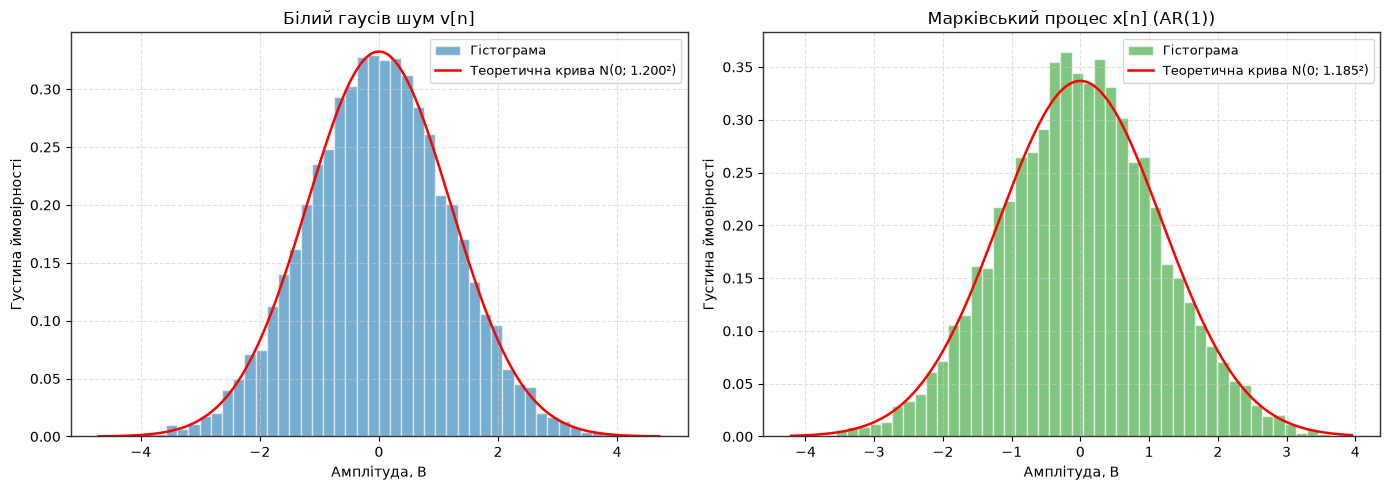

In [2]:
a_param = 0.85        # коефіцієнт зворотного зв'язку AR(1)
b_param = 0.52        # коефіцієнт підсилення AR(1)
sigma_v = 1.2         # СКВ білого шуму, В
N_samples = 10000     # довжина реалізації

L_s = 70              # довжина зондуючого сигналу, відліків
n0 = 220              # затримка сигналу в каналі, відліків
sigma_ch = 2.0        # СКВ шуму каналу, В

np.random.seed(42)    # щоб результат відтворювався

# білий гаусів шум v[n] ~ N(0, sigma_v^2)
v_white = np.random.normal(0.0, sigma_v, N_samples)

# марківський процес AR(1): x[n] = a*x[n-1] + b*v[n]
x_markov = signal.lfilter([b_param], [1.0, -a_param], v_white)


def calculate_statistics(seq_data, name_str):
    """Вибіркове середнє, незсунена дисперсія (ddof=1) та СКВ послідовності"""
    mean_val = np.mean(seq_data)
    var_val = np.var(seq_data, ddof=1)
    std_val = np.sqrt(var_val)
    print(f"{name_str:>26}: середнє = {mean_val:8.4f} В, дисперсія = {var_val:7.4f} В^2, СКВ = {std_val:7.4f} В")
    return mean_val, var_val, std_val


# теоретична дисперсія марківського процесу: b^2 * sigma_v^2 / (1 - a^2)
var_markov_theor = b_param ** 2 * sigma_v ** 2 / (1.0 - a_param ** 2)

print("--- СТАТИСТИЧНІ ХАРАКТЕРИСТИКИ ---")
print(f"a = {a_param}, b = {b_param}, sigma_v = {sigma_v} В, N = {N_samples}; "
      f"|a| < 1: {abs(a_param) < 1}")
mean_w, var_w, std_w = calculate_statistics(v_white, "Білий шум v[n]")
mean_m, var_m, std_m = calculate_statistics(x_markov, "Марківський процес x[n]")
print(f"Теоретичні значення: білий шум - M = 0, D = {sigma_v ** 2:.4f} В^2, СКВ = {sigma_v:.4f} В; "
      f"AR(1) - M = 0, D = {var_markov_theor:.4f} В^2, СКВ = {np.sqrt(var_markov_theor):.4f} В")
print(f"Відносне відхилення дисперсій: білий шум {100 * (var_w / sigma_v ** 2 - 1):+.2f} %, "
      f"AR(1) {100 * (var_m / var_markov_theor - 1):+.2f} %")

# гістограми з теоретичними кривими Гаусса
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, sig_theor, c, title in (
        (axes[0], v_white, sigma_v, '#1f77b4', "Білий гаусів шум v[n]"),
        (axes[1], x_markov, np.sqrt(var_markov_theor), '#2ca02c', "Марківський процес x[n] (AR(1))")):
    ax.hist(data, bins=50, density=True, color=c, alpha=0.6, edgecolor='white', label='Гістограма')
    u_axis = np.linspace(data.min(), data.max(), 400)
    pdf = np.exp(-u_axis ** 2 / (2 * sig_theor ** 2)) / (sig_theor * np.sqrt(2 * np.pi))
    ax.plot(u_axis, pdf, 'r-', lw=1.8, label=f'Теоретична крива N(0; {sig_theor:.3f}²)')
    ax.set_title(title)
    ax.set_xlabel("Амплітуда, В")
    ax.set_ylabel("Густина ймовірності")
    ax.grid(True)
    ax.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig("figures/noise_histograms.png", dpi=300)
plt.show()

**Результати статистичного аналізу** ($N = 10000$):

| Процес | Середнє, В | Дисперсія, В² | СКВ, В | Теор. дисперсія, В² | Теор. СКВ, В | Відхилення дисперсії |
|---|---|---|---|---|---|---|
| Білий шум $v[n]$ | −0.0026 | 1.4500 | 1.2042 | 1.4400 | 1.2000 | +0.69 % |
| AR(1) $x[n]$ | −0.0088 | 1.3204 | 1.1491 | 1.4032 | 1.1845 | −5.90 % |

Середні обох процесів близькі до нуля, а дисперсія білого шуму збігається з теоретичною (відхилення 0.69 %). Для марківського процесу відхилення дисперсії більше (−5.90 %). Причина — кореляція сусідніх відліків: ефективна кількість незалежних відліків $N_{eff} \approx N \dfrac{1 - a^2}{1 + a^2} \approx 1611$, тому стандартна похибка оцінки дисперсії становить близько $\sqrt{2 / N_{eff}} \approx 3.5\ \%$, і отримане відхилення (≈ 1.7 стандартної похибки) не виходить за межі статистичного розкиду. Гістограми обох процесів мають гаусів вигляд, але AR(1) має дещо меншу ширину, ніж $\sigma_v$ (множник $b / \sqrt{1 - a^2} = 0.987$).

### Блок 3. Нормовані автокореляційні функції білого шуму та марківського процесу


--- АВТОКОРЕЛЯЦІЙНІ ФУНКЦІЇ ---
Білий шум: max|r[m]| при m != 0 = 0.0242 (очікується порядку 1/sqrt(N) = 0.0100), інтервал кореляції = 0
  m   r_xx[m] (оцінка)   a^|m| (теорія)
  0             1.0000           1.0000
  1             0.8386           0.8500
  2             0.7043           0.7225
  3             0.5943           0.6141
  5             0.4236           0.4437
  6             0.3577           0.3771
  7             0.3051           0.3206
 10             0.1878           0.1969
Оцінка коефіцієнта a за r[1]: 0.8386 (задано a = 0.85)
Інтервал кореляції марківського процесу: теоретичний m_k = -1/ln(a) = 6.15 відліків, практичний (перший зсув з r < 1/e = 0.3679) = 6 відліків (з лінійною інтерполяцією 5.85)


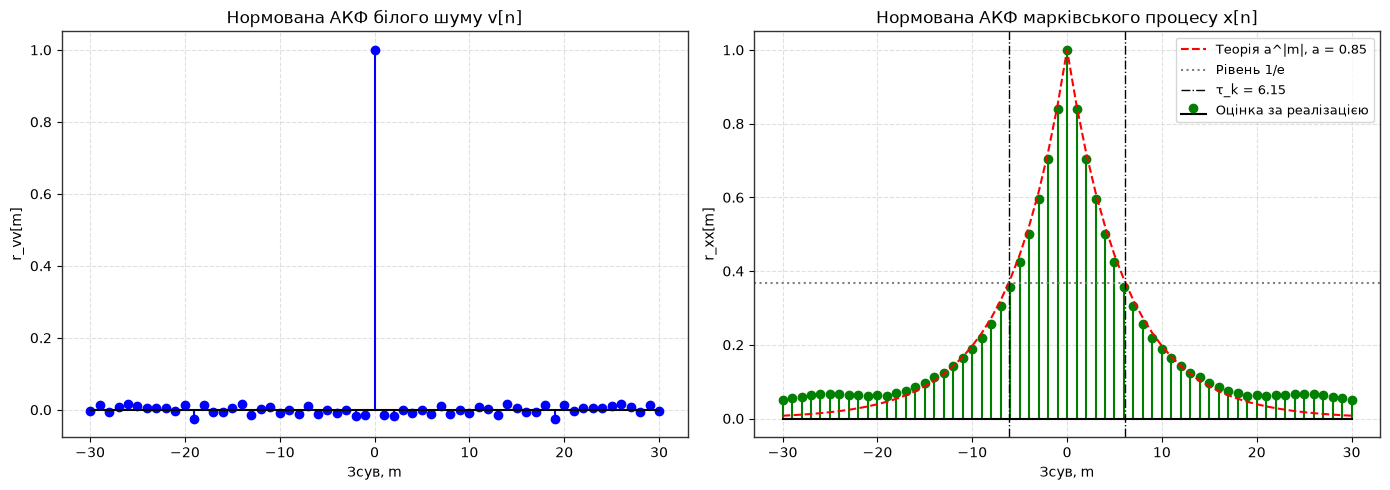

In [3]:
def compute_autocorrelation(data_seq, max_lags):
    """Нормована АКФ r[m] = R[m] / R[0] для зсувів m = -max_lags ... +max_lags"""
    centered = data_seq - np.mean(data_seq)
    full_corr = signal.correlate(centered, centered, mode='full')
    mid = len(data_seq) - 1                       # положення нульового зсуву
    r_vals = full_corr[mid - max_lags: mid + max_lags + 1] / full_corr[mid]
    return np.arange(-max_lags, max_lags + 1), r_vals


max_lags = 30
lags, r_white = compute_autocorrelation(v_white, max_lags)
_, r_markov = compute_autocorrelation(x_markov, max_lags)

# теоретична АКФ марківського процесу r[m] = a^|m|
r_markov_theor = a_param ** np.abs(lags)

# інтервал кореляції: зсув, на якому АКФ спадає в e разів
level_e = np.exp(-1.0)
m_k_theor = -1.0 / np.log(abs(a_param))
pos = lags >= 0
below = np.where(r_markov[pos] < level_e)[0]
m_k_pract = int(below[0])                     # перший зсув, на якому АКФ стала меншою за 1/e
m_k_interp = (below[0] - 1) + (r_markov[pos][below[0] - 1] - level_e) / (r_markov[pos][below[0] - 1] - r_markov[pos][below[0]])

mask_nz = lags != 0
print("\n--- АВТОКОРЕЛЯЦІЙНІ ФУНКЦІЇ ---")
print(f"Білий шум: max|r[m]| при m != 0 = {np.max(np.abs(r_white[mask_nz])):.4f} "
      f"(очікується порядку 1/sqrt(N) = {1 / np.sqrt(N_samples):.4f}), інтервал кореляції = 0")
print(f"{'m':>3} {'r_xx[m] (оцінка)':>18} {'a^|m| (теорія)':>16}")
for m in (0, 1, 2, 3, 5, 6, 7, 10):
    i_m = m + max_lags
    print(f"{m:3d} {r_markov[i_m]:18.4f} {r_markov_theor[i_m]:16.4f}")
print(f"Оцінка коефіцієнта a за r[1]: {r_markov[max_lags + 1]:.4f} (задано a = {a_param})")
print(f"Інтервал кореляції марківського процесу: теоретичний m_k = -1/ln(a) = {m_k_theor:.2f} відліків, "
      f"практичний (перший зсув з r < 1/e = {level_e:.4f}) = {m_k_pract} відліків "
      f"(з лінійною інтерполяцією {m_k_interp:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].stem(lags, r_white, linefmt='b-', markerfmt='bo', basefmt='k-')
axes[0].set_title("Нормована АКФ білого шуму v[n]")
axes[0].set_xlabel("Зсув, m")
axes[0].set_ylabel("r_vv[m]")
axes[0].grid(True)

axes[1].stem(lags, r_markov, linefmt='g-', markerfmt='go', basefmt='k-', label='Оцінка за реалізацією')
axes[1].plot(lags, r_markov_theor, 'r--', lw=1.5, label=f'Теорія a^|m|, a = {a_param}')
axes[1].axhline(level_e, color='gray', ls=':', label='Рівень 1/e')
axes[1].axvline(m_k_theor, color='k', ls='-.', lw=1.0, label=f'τ_k = {m_k_theor:.2f}')
axes[1].axvline(-m_k_theor, color='k', ls='-.', lw=1.0)
axes[1].set_title("Нормована АКФ марківського процесу x[n]")
axes[1].set_xlabel("Зсув, m")
axes[1].set_ylabel("r_xx[m]")
axes[1].grid(True)
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig("figures/acf_comparison.png", dpi=300)
plt.show()

**Результати кореляційного аналізу:**

| Зсув $m$ | $r_{xx}[m]$ (оцінка) | $a^{\lvert m \rvert}$ (теорія) |
|---|---|---|
| 0 | 1.0000 | 1.0000 |
| 1 | 0.8386 | 0.8500 |
| 2 | 0.7043 | 0.7225 |
| 3 | 0.5943 | 0.6141 |
| 5 | 0.4236 | 0.4437 |
| 6 | 0.3577 | 0.3771 |
| 7 | 0.3051 | 0.3206 |
| 10 | 0.1878 | 0.1969 |

АКФ білого шуму при $m \ne 0$ не перевищує 0.0242 за модулем, тобто має вигляд дельта-імпульсу з розкидом порядку $1 / \sqrt{N} = 0.01$ (максимум за багатьох зсувів — кілька $1 / \sqrt{N}$), тому інтервал кореляції білого шуму дорівнює нулю. АКФ марківського процесу експоненційно загасає за законом $a^{|m|}$; оцінка завжди трохи нижча за теоретичну (на 0.01–0.02), що узгоджується із зсувом оцінки дисперсії. Оцінка параметра $a$ за $r[1]$ дорівнює 0.8386 (задано 0.85).

Інтервал кореляції: теоретичний $m_k = -1 / \ln a = 6.15$ відліку, практичний (перший зсув із $r < e^{-1} = 0.3679$) — 6 відліків (5.85 з лінійною інтерполяцією). Спектр AR(1) — низькочастотний, його ширина обернено пропорційна інтервалу кореляції.

### Блок 4. Локаційне виявлення сигналу за допомогою взаємної кореляційної функції


--- ЛОКАЦІЙНЕ ВИЯВЛЕННЯ ЗА ВКФ ---
Зондуючий сигнал: код Баркера-7 [1, 1, 1, -1, -1, 1, -1], L_s = 70 відліків (10 відліків на біт), A0 = 1.0 В, енергія E_s = 70
Канал: N_y = 600, n0 = 220, sigma_ch = 2.0 В
SNR каналу (на інтервалі сигналу): -6.02 дБ; виграш від накопичення 10*lg(L_s) = 18.45 дБ
Пік ВКФ: R_ys[220] = 71.61 (очікується E_s = 70), СКВ шуму на виході кореляції = sigma_ch*sqrt(E_s) = 16.73
Найбільший побічний максимум ВКФ: 36.63 (відношення піка до нього 1.96)
Істинна затримка: 220, оцінена: 220, абсолютна похибка: 0 відліків
Бічні пелюстки АКФ коду (|m| >= 10): 10 при піку 70 (-16.9 дБ)
Статистика за 1000 реалізаціями шуму: точно (похибка 0) - 58.4 %, з похибкою не більше 1 відліку - 80.6 %, не більше 10 відліків (1 біт) - 93.6 %, хибне виявлення - 6.4 %


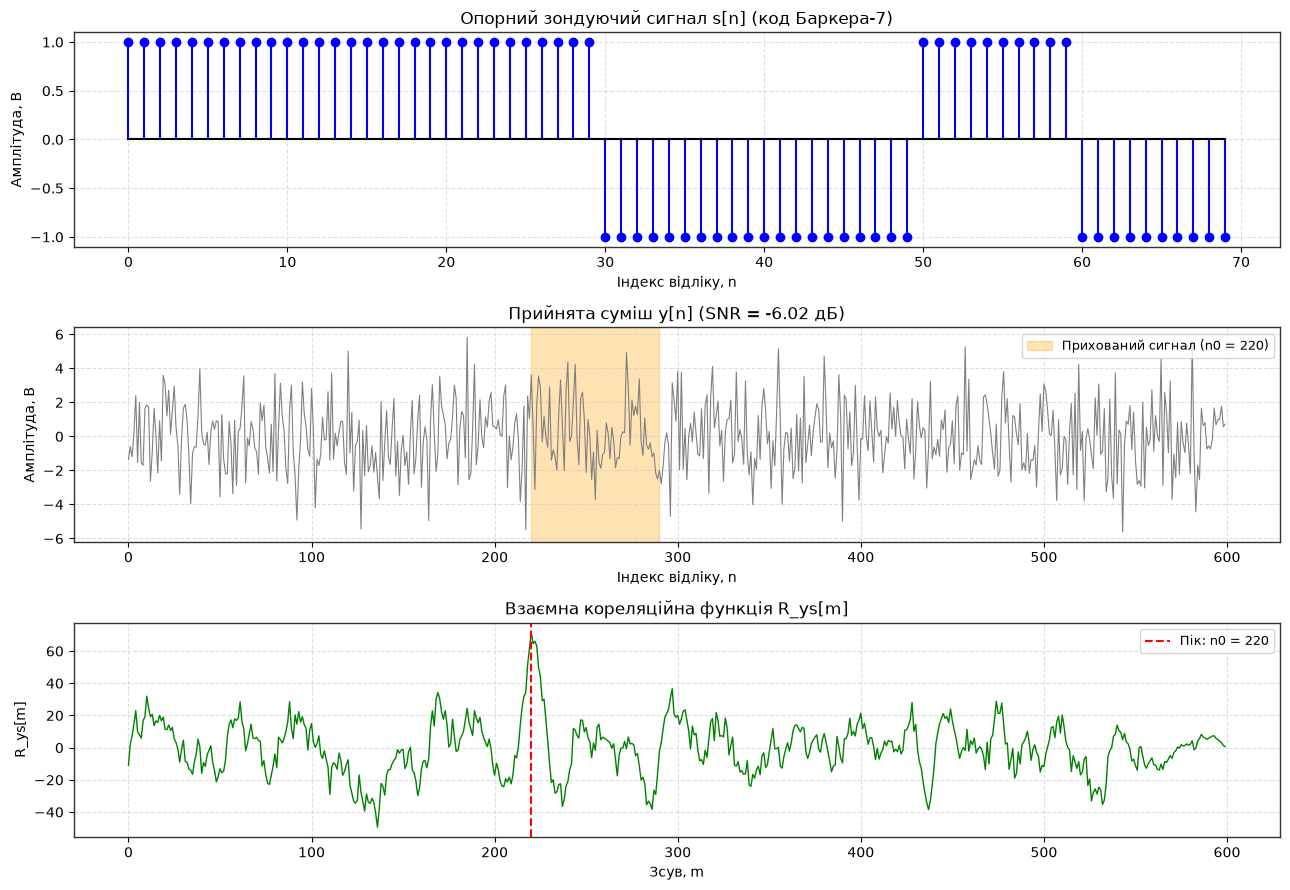


Моделювання завершено. Графіки збережено в 'figures/'.


In [4]:
# зондуючий сигнал: код Баркера довжиною 7 біт, кожен біт займає L_s / 7 = 10 відліків
barker_code = np.array([1, 1, 1, -1, -1, 1, -1], dtype=float)
A0 = 1.0
chip_len = L_s // len(barker_code)
s_probe = A0 * np.repeat(barker_code, chip_len)

# модель каналу: y[n] = s[n - n0] + xi[n]
N_y = 600
y_received = np.random.normal(0.0, sigma_ch, N_y)
y_received[n0:n0 + L_s] += s_probe

# ВКФ R_ys[m] = sum_n y[n] * s[n - m]
corr_full = signal.correlate(y_received, s_probe, mode='full')
lags_full = signal.correlation_lags(len(y_received), len(s_probe), mode='full')
r_ys_pos = corr_full[lags_full >= 0]              # від'ємні зсуви відкидаємо
lags_pos = lags_full[lags_full >= 0]

n0_estimated = int(lags_pos[np.argmax(r_ys_pos)])
snr_channel_db = 10.0 * np.log10(np.mean(s_probe ** 2) / sigma_ch ** 2)
e_probe = np.sum(s_probe ** 2)                    # енергія зондуючого сигналу
gain_db = 10.0 * np.log10(L_s)                    # виграш від когерентного накопичення

# автокореляція самого коду (для бічних пелюсток)
acf_code = np.correlate(s_probe, s_probe, mode='full')
lags_code = np.arange(-(len(s_probe) - 1), len(s_probe))
sidelobe = np.max(np.abs(acf_code[np.abs(lags_code) >= chip_len]))     # поза головною пелюсткою (|m| < 10)

print("\n--- ЛОКАЦІЙНЕ ВИЯВЛЕННЯ ЗА ВКФ ---")
print(f"Зондуючий сигнал: код Баркера-7 {barker_code.astype(int).tolist()}, "
      f"L_s = {L_s} відліків ({chip_len} відліків на біт), A0 = {A0} В, енергія E_s = {e_probe:.0f}")
print(f"Канал: N_y = {N_y}, n0 = {n0}, sigma_ch = {sigma_ch} В")
print(f"SNR каналу (на інтервалі сигналу): {snr_channel_db:.2f} дБ; "
      f"виграш від накопичення 10*lg(L_s) = {gain_db:.2f} дБ")
print(f"Пік ВКФ: R_ys[{n0_estimated}] = {np.max(r_ys_pos):.2f} (очікується E_s = {e_probe:.0f}), "
      f"СКВ шуму на виході кореляції = sigma_ch*sqrt(E_s) = {sigma_ch * np.sqrt(e_probe):.2f}")
second_peak = np.max(np.delete(r_ys_pos, slice(max(n0_estimated - chip_len, 0), n0_estimated + chip_len + 1)))
print(f"Найбільший побічний максимум ВКФ: {second_peak:.2f} (відношення піка до нього {np.max(r_ys_pos) / second_peak:.2f})")
print(f"Істинна затримка: {n0}, оцінена: {n0_estimated}, абсолютна похибка: {abs(n0 - n0_estimated)} відліків")
print(f"Бічні пелюстки АКФ коду (|m| >= {chip_len}): {sidelobe:.0f} при піку {np.max(acf_code):.0f} "
      f"({20 * np.log10(sidelobe / np.max(acf_code)):.1f} дБ)")

# статистика виявлення за 1000 незалежних реалізацій шуму каналу
n_trials = 1000
errors = np.zeros(n_trials, dtype=int)
for i in range(n_trials):
    y_trial = np.random.normal(0.0, sigma_ch, N_y)
    y_trial[n0:n0 + L_s] += s_probe
    r_trial = signal.correlate(y_trial, s_probe, mode='full')[len(s_probe) - 1:]
    errors[i] = int(np.argmax(r_trial)) - n0
print(f"Статистика за {n_trials} реалізаціями шуму: точно (похибка 0) - {100 * np.mean(errors == 0):.1f} %, "
      f"з похибкою не більше 1 відліку - {100 * np.mean(np.abs(errors) <= 1):.1f} %, "
      f"не більше {chip_len} відліків (1 біт) - {100 * np.mean(np.abs(errors) <= chip_len):.1f} %, "
      f"хибне виявлення - {100 * np.mean(np.abs(errors) > chip_len):.1f} %")

fig, axes = plt.subplots(3, 1, figsize=(13, 9))

axes[0].stem(np.arange(L_s), s_probe, linefmt='b-', markerfmt='bo', basefmt='k-')
axes[0].set_title("Опорний зондуючий сигнал s[n] (код Баркера-7)")
axes[0].set_xlabel("Індекс відліку, n")
axes[0].set_ylabel("Амплітуда, В")
axes[0].grid(True)

axes[1].plot(np.arange(N_y), y_received, color='gray', lw=0.8)
axes[1].axvspan(n0, n0 + L_s, color='orange', alpha=0.3, label=f'Прихований сигнал (n0 = {n0})')
axes[1].set_title(f"Прийнята суміш y[n] (SNR = {snr_channel_db:.2f} дБ)")
axes[1].set_xlabel("Індекс відліку, n")
axes[1].set_ylabel("Амплітуда, В")
axes[1].grid(True)
axes[1].legend(loc='upper right', fontsize=9)

axes[2].plot(lags_pos, r_ys_pos, 'g-', lw=1.0)
axes[2].axvline(n0_estimated, color='r', ls='--', label=f'Пік: n0 = {n0_estimated}')
axes[2].set_title("Взаємна кореляційна функція R_ys[m]")
axes[2].set_xlabel("Зсув, m")
axes[2].set_ylabel("R_ys[m]")
axes[2].grid(True)
axes[2].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig("figures/radar_detection_ccf.png", dpi=300)
plt.show()

print("\nМоделювання завершено. Графіки збережено в 'figures/'.")

**Результати локаційного виявлення сигналу:**

| Величина | Значення |
|---|---|
| Зондуючий сигнал | Баркер-7, 10 відліків на біт, $L_s = 70$, $E_s = 70$ |
| SNR каналу на вході | −6.02 дБ |
| Виграш від накопичення $10 \lg L_s$ | 18.45 дБ |
| Пік ВКФ $R_{ys}[220]$ | 71.61 (очікувалось $E_s = 70$) |
| СКВ шуму на виході корелятора | 16.73 |
| Найбільший побічний максимум ВКФ | 36.63 (відношення пік / побічний = 1.96) |
| Істинна затримка $n_0$ / оцінена | 220 / 220, похибка 0 відліків |
| Бічні пелюстки АКФ коду ($\lvert m \rvert \ge 10$) | 10 при піку 70 (−16.9 дБ) |

Сигнал на вході знаходиться нижче рівня шуму (SNR = −6 дБ), і за часовою реалізацією його не видно. Взаємна кореляція з еталонним кодом накопичує енергію (пік 71.61, що збігається з $E_s = 70$ з поправкою на шум), а шум на виході корелятора має СКВ 16.73. У цій реалізації пік затримки оцінено правильно ($\hat n_0 = 220$), але відношення до найбільшого побічного максимуму лише 1.96, тобто запас невеликий.

Статистика за 1000 реалізаціями шуму показує, що виявлення не завжди ідеальне: точна оцінка затримки (похибка 0) — 58.4 %, похибка не більше 1 відліку — 80.6 %, не більше 10 відліків (1 біт) — 93.6 %, хибне виявлення (похибка більше за біт) — 6.4 %. Це узгоджується з відношенням пік/шум на виході $\approx 4.2$ (12.4 дБ): за кількох сотень зсувів окремі шумові викиди можуть досягати рівня піка, а сама верхівка ВКФ внаслідок шуму зміщується на відліки поруч із $n_0$ (ширина піка в межах біта).

## 5. Висновки

1. Для білого шуму оцінки збігаються з теорією ($\hat{D} = 1.4500$ проти 1.4400 В², відхилення 0.69 %), а АКФ має вигляд дельта-імпульсу ($\max |r[m \ne 0]| = 0.0242$), тобто інтервал кореляції дорівнює нулю. Дисперсія марківського процесу AR(1) (1.3204 проти 1.4032 В², −5.90 %) відхиляється сильніше через кореляцію відліків: ефективна вибірка $N_{eff} \approx 1611$ замість 10000, стандартна похибка близько 3.5 %.

2. АКФ процесу AR(1) спадає за експонентою $a^{|m|}$; інтервал кореляції для $a = 0.85$ теоретично $6.15$ відліку, за вибіркою — 6 відліків. Чим ближче $a$ до 1, тим довший інтервал кореляції і вужчий спектр процесу.

3. Взаємна кореляція зі сигналом-еталоном дозволила виявити код Баркера-7 (70 відліків) при SNR на вході $-6.02$ дБ: виграш від накопичення $10 \lg 70 = 18.45$ дБ, пік ВКФ 71.61 при очікуваних 70, затримку $n_0 = 220$ оцінено без похибки.

4. Моделювання 1000 реалізацій показало, що за такого SNR виявлення стійке не повністю: затримку оцінено точно у 58.4 % випадків, у межах 1 відліку — у 80.6 %, у межах біта — у 93.6 %, хибне виявлення — 6.4 %. Для підвищення надійності треба збільшувати довжину або енергію коду (наприклад, використовувати довші коди Баркера, ЛЧМ-імпульс) чи зменшувати рівень шуму.

5. Код Баркера дає вузький головний пік і низькі бічні пелюстки АКФ (−16.9 дБ), що робить його придатним для вимірювання дальності за ВКФ.

## Відповідь на контрольні питання

**1. У чому полягає фізична та статистична відмінність між поняттями стаціонарного у широкому сенсі та ергодичного випадкового процесу?**

* **Стаціонарний у широкому сенсі (WSS — Wide-Sense Stationary) процес:**
* *Статистично:* Математичне сподівання процесу є постійним у часі ($m_x[n] = \mathbb{E}\{x[n]\} = \text{const}$), дисперсія скінченна, а автокореляційна функція (АКФ) залежить лише від часового зсуву $m = n_2 - n_1$, а не від абсолютних моментів часу:

$$R_{xx}[n_1, n_2] = \mathbb{E}\{x[n_1]x^*[n_2]\} = R_{xx}[m]$$


* *Фізично:* Характеристики джерела шуму або генератора сигналу залишаються незмінними в часі (режим роботи усталений), проте для обчислення статистичних моментів (середнього, дисперсії, АКФ) теоретично потрібно усереднювати значення **по ансамблю** (великій кількості незалежних реалізацій процесу в один і той самий момент часу).


* **Ергодичний процес:**
* *Статистично:* Це підклас стаціонарних процесів, для яких усереднення **по часу** вздовж однієї нескінченно тривалої реалізації з ймовірністю $1$ збігається зі статистичним усередненням **по ансамблю** реалізацій:

$$\lim_{N \to \infty} \frac{1}{2N + 1}\sum_{n=-N}^{N} x[n] = \mathbb{E}\{x[n]\}, \qquad \lim_{N \to \infty} \frac{1}{2N + 1}\sum_{n=-N}^{N} x[n]x^*[n - m] = R_{xx}[m]$$


* *Фізично:* Кожна окрема реалізація за достатньо великий проміжок часу проходить через усі можливі статистичні стани системи з тією самою ймовірністю, що й уся сукупність реалізацій. Це дозволяє на практиці оцінювати статистичні параметри сигналу за одним експериментальним записом. (Будь-який ергодичний процес є стаціонарним, але не кожен стаціонарний процес є ергодичним).



---

**2. Які властивості має автокореляційна функція (АКФ) стаціонарного дискретного сигналу в точці нульового часового зсуву ($m = 0$) та при віддаленні від початку координат ($m \to \infty$)?**

* **У точці нульового часового зсуву ($m = 0$):**
* АКФ досягає свого **глобального максимуму**: $\vert{}R_{xx}[m]\vert{} \le R_{xx}[0]$ для будь-якого зсуву $m$.
* Значення $R_{xx}[0]$ завжди є дійсним невід'ємним числом і дорівнює **повній середній потужності** (середньому квадрату амплітуди) сигналу:

$$R_{xx}[0] = \mathbb{E}\{\vert{}x[n]\vert{}^2\} = \sigma_x^2 + \vert{}\mu_x\vert{}^2$$



Для центрованого процесу з нульовим математичним сподіванням ($\mu_x = 0$) значення $R_{xx}[0]$ чисельно дорівнює дисперсії $\sigma_x^2$.


* **При віддаленні від початку координат ($m \to \infty$):**
* Для чисто випадкових (неперіодичних) стаціонарних сигналів статистичний зв'язок між віддаленими в часі відліками поступово слабшає і зникає (відбувається декорреляція), тому АКФ асимптотично прямує до квадрата математичного сподівання (потужності постійної складової):

$$\lim_{m \to \infty} R_{xx}[m] = \vert{}\mu_x\vert{}^2$$


* Якщо процес центрований ($\mu_x = 0$), то $\lim_{m \to \infty} R_{xx}[m] = 0$. (Якщо ж сигнал містить детерміновану періодичну складову, АКФ при $m \to \infty$ не затухає до нуля, а переходить у незгасаючі періодичні коливання).



---

**3. Чому автокореляційна функція дискретного білого шуму має вигляд дискретного імпульсу Кронекера $\sigma^2 \delta[m]$, і яке значення має його інтервал кореляції?**

* **Причина вигляду $\sigma^2 \delta[m]$:** Дискретний білий шум $w[n]$ за визначенням є послідовністю некорельованих між собою випадкових відліків із нульовим середнім ($\mathbb{E}\{w[n]\} = 0$) та сталою дисперсією $\sigma^2$:
* При $m = 0$ кожен відлік повністю корелює сам із собою: $R_{ww}[0] = \mathbb{E}\{\vert{}w[n]\vert{}^2\} = \sigma^2$.
* При будь-якому ненульовому зсуві $m \neq 0$ відліки $w[n]$ і $w[n-m]$ статистично некорельовані: $R_{ww}[m] = \mathbb{E}\{w[n]\}\mathbb{E}\{w^*[n-m]\} = 0$.
Оскільки символ Кронекера дорівнює $\delta[0] = 1$ та $\delta[m] = 0$ при $m \neq 0$, АКФ записується як $R_{ww}[m] = \sigma^2 \delta[m]$.


* **Значення інтервалу кореляції:** Інтервал кореляції дискретного білого шуму дорівнює **нулю** ($\tau_k = 0$ або один період дискретизації $T_s$ при переході до неперервного масштабу часу). Це означає повну відсутність статистичної «пам'яті» між сусідніми відліками: кореляційний зв'язок зникає вже при найменшому дискретному зсуві $m = \pm 1$.

---

**4. Яким чином коефіцієнт зворотного зв'язку $a$ в моделі марківського авторегресійного процесу першого порядку $\text{AR}(1)$ впливає на ширину інтервалу кореляції $\tau_k$ та форму спектральної щільності потужності?**

Модель $\text{AR}(1)$ описується рівнянням $x[n] = a x[n - 1] + w[n]$ (де $\vert{}a\vert{} < 1$ — умова стійкості та стаціонарності, $w[n]$ — білий шум з дисперсією $\sigma_w^2$), а її нормована АКФ спадає за експоненційним законом $\rho[m] = a^{\vert{}m\vert{}}$.

* **Вплив на ширину інтервалу кореляції $\tau_k$:**
* Інтервал кореляції (виражений у кількості відліків $m_k \approx \frac{1}{1 - \vert{}a\vert{}}$ або $m_k = -\frac{1}{\ln \vert{}a\vert{}}$, у часі $\tau_k = m_k T_s$) визначається швидкістю затухання АКФ.
* Зі збільшенням модуля $\vert{}a\vert{} \to 1$ посилюється інерційність («пам'ять») системи, АКФ затухає дуже повільно, і **інтервал кореляції $\tau_k$ суттєво розширюється** ($\tau_k \to \infty$).
* Зі зменшенням $\vert{}a\vert{} \to 0$ зв'язок між сусідніми відліками слабшає, **інтервал кореляції звужується** ($\tau_k \to 0$), і при $a = 0$ процес перетворюється на білий шум.


* **Вплив на форму спектральної щільності потужності (PSD):**

$$S_{xx}(e^{j\omega}) = \frac{\sigma_w^2}{\vert{}1 - a e^{-j\omega}\vert{}^2} = \frac{\sigma_w^2}{1 - 2a \cos\omega + a^2}$$


* При $a = 0$ спектр є рівномірним (плоским) по всій смузі частот.
* При $a > 0$ (особливо при $a \to 1$) потужність концентрується в **низькочастотній області** ($\omega \approx 0$), формуючи вузький і високий низькочастотний спектральний пік («червоний» шум).
* При $a < 0$ (особливо при $a \to -1$) сигнал швидко змінює знак на кожному кроці, тому енергія зосереджується поблизу **високих частот** біля межі Найквіста ($\omega \approx \pi$, «синій» шум).



---

**5. У чому полягає сутність теореми Вінера-Хінчіна, і як пов'язані між собою автокореляційна функція сигналу та його спектральна щільність потужності (Power Spectral Density — PSD)?**

* **Сутність теореми Вінера-Хінчіна:** Теорема стверджує, що для стаціонарного у широкому сенсі випадкового процесу автокореляційна функція (АКФ) у часовій області та спектральна щільність потужності (PSD) у частотній області утворюють **пару перетворень Фур'є**. Це дає змогу перейти від статистичного опису випадкового процесу в часі до розподілу його середньої потужності за частотами навіть тоді, коли окремі реалізації нескінченного сигналу не мають класичного перетворення Фур'є.
* **Математичний зв'язок між АКФ та PSD:**
* **Пряме перетворення Фур'є від АКФ** дає спектральну щільність потужності:

$$S_{xx}(e^{j\omega}) = \sum_{m=-\infty}^{\infty} R_{xx}[m] e^{-j\omega m}$$


* **Обернене перетворення Фур'є від PSD** відновлює автокореляційну функцію:

$$R_{xx}[m] = \frac{1}{2\pi} \int_{-\pi}^{\pi} S_{xx}(e^{j\omega}) e^{j\omega m} \, d\omega$$


* Зокрема, при $m = 0$ площа під кривою PSD дорівнює повній середній потужності сигналу $R_{xx}[0]$, а завдяки ермітовій симетрії $R_{xx}[m] = R_{xx}^*[-m]$ функція $S_{xx}(e^{j\omega})$ завжди є дійсною та невід'ємною.



---

**6. Чому функція взаємної кореляції (ВКФ) досягає свого екстремуму в момент збігу часових зсувів двох сигналів, і яким чином це дозволяє виявляти сигнали при співвідношенні сигнал/шум $\text{SNR} \ll 0\text{ дБ}$?**

* **Причина екстремуму в момент збігу зсувів:** Нехай прийнятий сигнал має вигляд $y[n] = s[n - n_0] + w[n]$, де $s[n - n_0]$ — затриманий на $n_0$ корисний сигнал, а $w[n]$ — адитивний шум. Функція взаємної кореляції з еталонним (опорним) сигналом $s[n]$ визначається як:

$$R_{ys}[m] = \sum_{n=0}^{N-1} y[n] s^*[n - m]$$



За нерівністю Коші-Буняковського скалярний добуток досягає максимуму тоді, коли часовий зсув еталона точно збігається із затримкою прийнятого сигналу ($m = n_0$). У цей момент усі $N$ відліків корисного сигналу перемножуються **синфазно** ($s[n - n_0]s^*[n - n_0] = \vert{}s[n - n_0]\vert{}^2 \ge 0$) і когерентно додаються, утворюючи чіткий пік, пропорційний повній енергії сигналу $E_s = \sum \vert{}s[n]\vert{}^2 \propto N$.
* **Виявлення сигналів при $\text{SNR} \ll 0\text{ дБ}$ (ефект когерентного накопичення):**
* Амплітуда кореляційного піку корисного сигналу зростає **лінійно** зі збільшенням бази (кількості відліків) сигналу $N$ (а його потужність — як $N^2$).
* Некорельований шум $w[n]$ має випадкові фази відліків, тому на виході корелятора накопичується **некогерентно** — його середня потужність зростає лише пропорційно $N$, а середньоквадратична амплітуда — як $\sqrt{N}$.
* В результаті відношення сигнал/шум на виході корелятора збільшується в $N$ разів (виграш обробки становить $10\log_{10} N\text{ дБ}$), що дозволяє впевнено виділити пік сигналу над рівнем шумів навіть тоді, коли на вході потужність шуму значно перевищує потужність сигналу ($\text{SNR} \ll 0\text{ дБ}$).



---

**7. Чим відрізняється поведінка кореляційного піку для простого гармонійного радіоімпульсу та для складного фазоманіпульованого сигналу (наприклад, коду Баркера або ЛЧМ-імпульсу)?**

* **Простий гармонійний радіоімпульс (прямокутна обвідна тривалістю $T$ без внутрішньоімпульсної модуляції):**
* Обвідна АКФ має форму широкого **трикутника** з основою $2T$ і шириною головного піку по рівню половини потужності $\Delta\tau \approx T$.
* Ширина піку (а отже, роздільна здатність за затримкою та точність вимірювання дистанції) жорстко обмежена тривалістю імпульсу $T$: для звуження піку доводиться скорочувати $T$, що зменшує енергію імпульсу і погіршує дальність виявлення. Полога вершина трикутника також ускладнює точну фіксацію моменту приходу сигналу на фоні шумів.


* **Складний сигнал із внутрішньоімпульсною модуляцією (код Баркера або ЛЧМ-імпульс із базою $B = \Delta F \cdot T \gg 1$):**
* Реалізується ефект **стиснення імпульсу (pulse compression)**: енергія накопичується протягом усього довгого імпульсу тривалістю $T$, але завдяки швидкій зміні фази за законом коду Баркера або лінійній зміні частоти (ЛЧМ) декорреляція настає вже при зміщенні на тривалість одного елементарного символу $\tau_0 = T/N$ або на величину $\Delta\tau \approx 1/\Delta F$.
* Кореляційний пік стає **у $B = \Delta F \cdot T$ разів вужчим** (гострим, голкоподібним) і у стільки ж разів вищим за потужністю, ніж у простого імпульсу тієї самої енергії, при низькому рівні бічних пелюсток (для коду Баркера довжиною $N$ бічні пелюстки не перевищують $1/N$ від головного максимуму). Це усуває суперечність між дальністю виявлення (яка визначається великою тривалістю $T$) та високою роздільною здатністю й точністю визначення затримки (які визначаються широкою смугою частот $\Delta F$).